In [1]:

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import colorcet as cc
import toolz as tz
import itertools as t
import random
import copy

from tqdm.auto import tqdm

from sklearn.metrics import confusion_matrix, balanced_accuracy_score, accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow import keras

plt.rcParams["scatter.edgecolors"] = "none"
plt.rcParams["savefig.bbox"] = 'tight'
plt.rcParams["axes.labelsize"] = 16
np.set_printoptions(legacy="1.21",linewidth=120)

Manejo de datos, ya usado e implementado en la versión anterior con pytorch con division 70% de entranimiento, 15% validacion y 15% test:

Text(0, 0.5, 'Fracción')

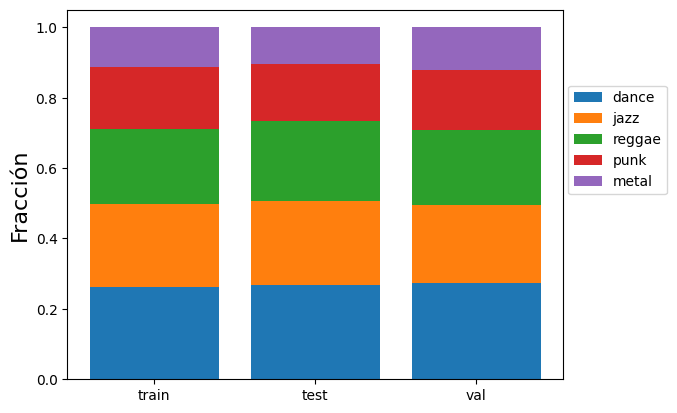

In [3]:
genres = ["dance","jazz","reggae","punk","metal"]
translation = dict(map(reversed,enumerate(genres)))

expr_genre_simplify_names = pl.col("genre").str.replace_many({" and electronica": ""," and blues": "","soul and ": ""})
expr_genre_passlist = pl.col("genre").is_in(genres)
expr_genre_to_int = pl.col("genre").replace_strict(translation)

data = (
    pl.scan_csv("genre_dataset.txt", skip_rows=9, quote_char=None, ignore_errors=True)
    .drop("track_id", "title", "artist_name")
    .rename({"%genre": "genre"})
    .with_columns(expr_genre_simplify_names)
    .filter(expr_genre_passlist)
    .with_columns(expr_genre_to_int)
    .unique(keep="first", maintain_order=True)
    .collect()
)

X = data.drop("genre").to_numpy()
y = data["genre"].to_numpy()

def split_thrice(*collections,train_size=0.7,test_size=np.nan,val_size=np.nan,**kwargs):
    """Like sklearn train_test_split but for three categories. kwargs are passed to the sklearn function.
    If two of the sizes are NaN, the other two are assumed equal. If all sizes are None, all are assumed equal.

    The return style is different from sklearn. Tuples with the train, test and validation samples are returned separately.
    """
    sizes = np.array([train_size,test_size,val_size])
    nan_count = np.isnan(sizes).sum()
    rest = 1-np.nansum(sizes)
    sizes[np.isnan(sizes)] = rest / nan_count
    train_size,test_size,val_size = sizes
    p = train_size
    q = test_size / (1-p)
    first_split = train_test_split(*collections,train_size=p,**kwargs)
    train, other = zip(*tz.partition(2,first_split))
    second_split = train_test_split(*other,train_size=q,**kwargs)
    test, val = zip(*tz.partition(2,second_split))
    return list(train), list(test), list(val)

train, test, val = split_thrice(X,y,train_size=0.7,val_size=0.15,shuffle=True)

for name,y_ in {"train":train[1],"test":test[1],"val":val[1]}.items():
    xs = np.histogram(y_,bins=np.arange(6)-0.5)[0]
    xs = xs/xs.sum()
    bottom = 0
    for i,x_ in enumerate(xs):
        plt.bar(name,x_,bottom=bottom,color=f"C{i}",label=(genres[i] if name=="train" else None))
        bottom += x_
plt.legend(loc=[1.01,0.5])
plt.ylabel("Fracción")

Para esta parte, al darnos cuenta de que la elección del modelo de entrenamiento, los parámetros y la arquitectura dependían entre sí, pues el análisis de la arquitectura depende del modelo de entrenamiento y del batch, y este a su vez depende de la tasa de aprendizaje elegida, se decidió realizar una búsqueda sobre los posibles modelos elegibles entre una serie de opciones dadas. Se escogieron 3 posibles capas, dado que más allá de este valor muestra sobreajuste, con 256, 128, 64, 32 o 16 neuronas en la capa, y con modelos de optimización: Adam, SGD, RMSprop, Adagrad; learning rates de 0.1, 0.01, 0.001, 0.0001; y tamaños de batch de 16, 32, 64 y 128 neuronas. Hacer una grilla exhaustiva de todos estos posibles valores es muy costoso, con 6.720 entrenamientos para una arquitectura de 3 capas. Probando para una arquitectura, entrenar con todas las posibles combinaciones de parámetros tarda aproximadamente 7 minutos en GPU de Colab, por lo que hacer todas las posibles combinaciones tardaría 3 días. De modo que se va a elegir al azar 70 combinaciones de los modelos propuestos (número de capas, configuración de neuronas, optimizador, learning rate, tamaño de batch), se entrenarán y se elegirá el de mayor accuracy.

In [11]:

capas_totales = 3
resultados_loss = {f'{i} capa(s)': {} for i in range(1, capas_totales +1)}
resultados_accuracy ={f'{i} capa(s)': {} for i in range(1, capas_totales +1)}
neuronas_posibles = [256, 128, 64, 32, 16]
N_conf_max = 15


optimizadores = [keras.optimizers.Adam, keras.optimizers.SGD,
                 keras.optimizers.AdamW,keras.optimizers.RMSprop,
                 keras.optimizers.Adagrad]

batch_sizes = [16, 32, 64, 128]
learning_rates = [0.1, 0.01, 0.001, 0.0001]


nombres_optimizadores = ["Adam", "SGD", "AdamW", "RMSprop", "Adagrad"]

normalizar = keras.layers.Normalization()
normalizar.adapt(train[0])

train_x = normalizar(train[0])
val_x = normalizar(val[0])
test_x = normalizar(test[0])



In [14]:
# Generación de posubles combinaciones
def generar_combinaciones(capas_totales, neuronas_posibles, optimizador, nombres_optimizadores,
                          learning_rates, batch_sizes, max_comb=70):
  combinaciones = []
  for n_capas in range(1, capas_totales + 1):
      configuraciones = list(t.product(neuronas_posibles, repeat=n_capas))

      for configuracion in configuraciones:
          for optimizador, nombre in zip(optimizadores, nombres_optimizadores):
              for lr in learning_rates:
                  for batch in batch_sizes:
                      combinaciones.append((n_capas, configuracion, optimizador, nombre, lr, batch))


  combinaciones = random.sample(combinaciones, min(max_comb, len(combinaciones)))

  return combinaciones

combinaciones = generar_combinaciones(capas_totales, neuronas_posibles, optimizadores, nombres_optimizadores, learning_rates, batch_sizes)

In [15]:
print("Algunas combinaciones")
print(*combinaciones[:5], sep="\n")

Algunas combinaciones
(3, (64, 64, 32), <class 'keras.src.optimizers.adagrad.Adagrad'>, 'Adagrad', 0.0001, 32)
(2, (16, 16), <class 'keras.src.optimizers.sgd.SGD'>, 'SGD', 0.01, 16)
(3, (256, 16, 16), <class 'keras.src.optimizers.sgd.SGD'>, 'SGD', 0.1, 128)
(2, (16, 32), <class 'keras.src.optimizers.adamw.AdamW'>, 'AdamW', 0.0001, 128)
(3, (256, 16, 256), <class 'keras.src.optimizers.adamw.AdamW'>, 'AdamW', 0.001, 16)


Para esta parte, para los posibles modelos se entrenó un modelo y se guardó el mejor resultado de *accuracy* y su respectivo valor de función de pérdida con todas las características de este modelo. Asimismo, se ejecutó un método de parada de `Keras` (`callbacks.EarlyStopping`), en el cual después de un número de épocas (`patience = 6` épocas), si no mejora el modelo o la `val_loss`, se detendrá con el fin de evitar un sobreajuste.

In [16]:
# Para cada diferente red se estima el modelo y se guarda la información de este en resultados
def entrenamiento_modelos(combinaciones, train_x, train, val_x, val, genre):
  resultados = []

  for n_capas, configuracion, optimizador, nombre, lr, batch in tqdm(combinaciones):

      keras.backend.clear_session()
      keras.utils.set_random_seed(42)

      modelo = keras.Sequential()
      modelo.add(keras.layers.Input(shape=(train_x.shape[1],)))

      for n_neuronas in configuracion:
          modelo.add(keras.layers.Dense(n_neuronas, activation="relu"))

      modelo.add(keras.layers.Dense(len(genres), activation="softmax"))

      modelo.compile(
          optimizer=optimizador(learning_rate=lr),
          loss="sparse_categorical_crossentropy",
          metrics=["accuracy"])

      parada = keras.callbacks.EarlyStopping(monitor="val_loss",mode="min",patience=6,restore_best_weights=True)

      historial = modelo.fit(
          train_x,
          train[1],
          validation_data=(val_x, val[1]),
          epochs=50,
          batch_size=batch,
          verbose=0, callbacks=[parada])

      i = int(np.argmax(historial.history["val_accuracy"]))

      resultados.append({
          "capas": n_capas,
          "configuracion": configuracion,
          "nombre optimizador": nombre,
          "Optimizador": optimizador,
          "learning_rate": lr,
          "batch_size": batch,
          "loss": historial.history["val_loss"][i],
          "accuracy": historial.history["val_accuracy"][i]})
  return resultados

In [17]:
resultados = entrenamiento_modelos(combinaciones, train_x, train, val_x, val, genres)
pd.DataFrame(resultados).to_csv("resultados.csv", index=False)

  0%|          | 0/70 [00:00<?, ?it/s]

Aca miramos el accuracy para cada una de estos modelos

In [29]:
df_resultados = pd.read_csv("resultados.csv")

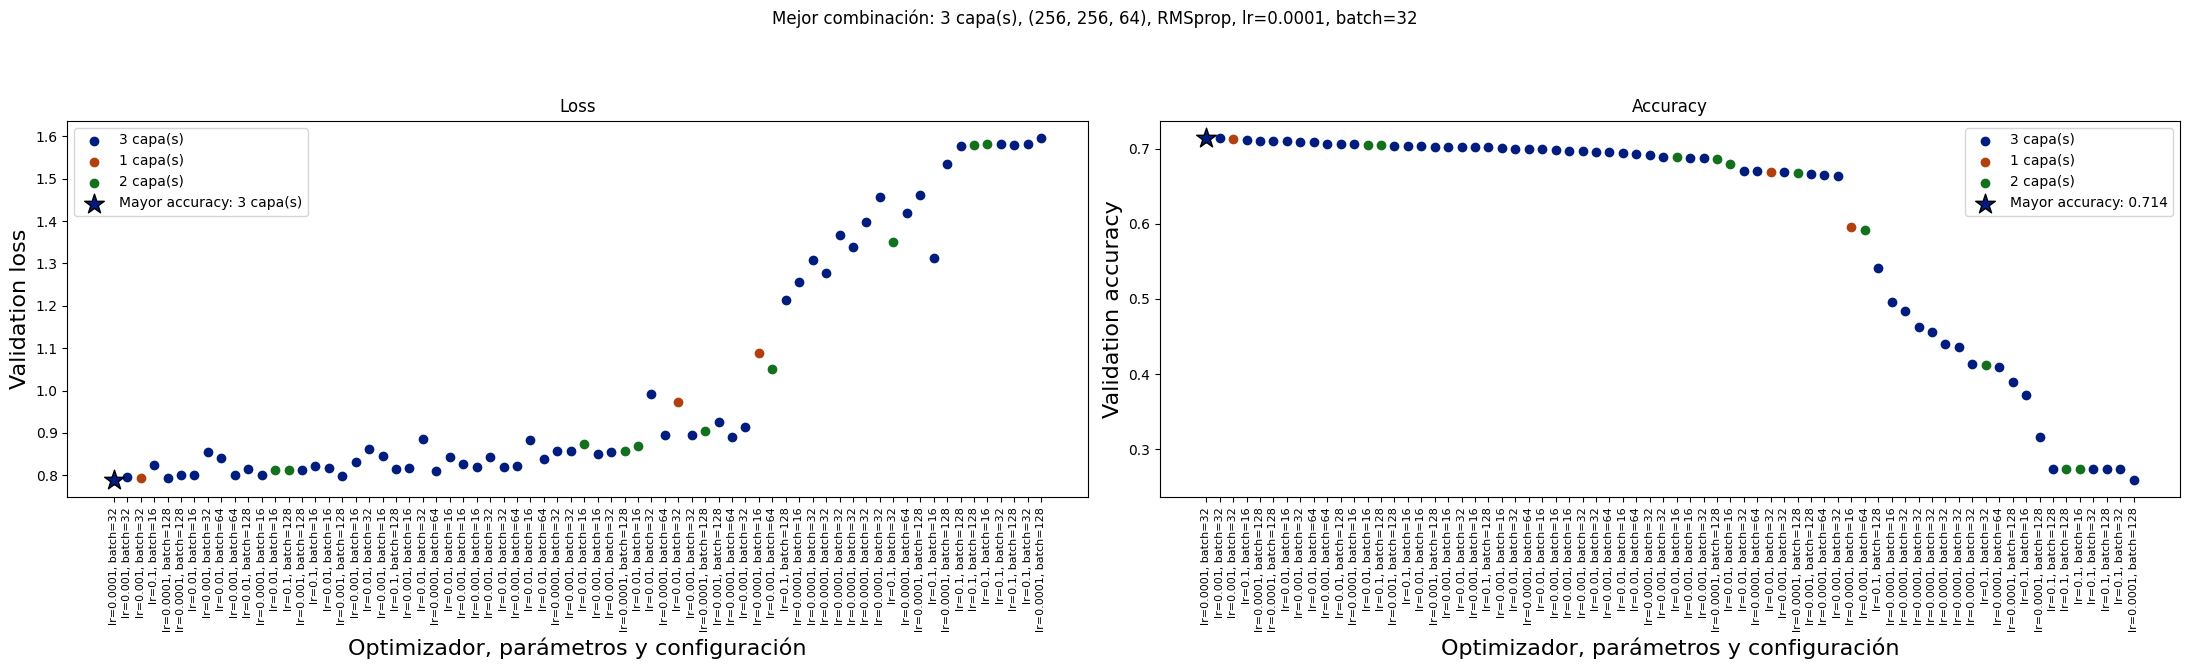

In [47]:
def graficar_resultados(resultados):
    resultados_ordenados = resultados.sort_values("accuracy", ascending=False).reset_index(drop=True)

    x = np.arange(len(resultados_ordenados))
    etiquetas = [f'lr={r["learning_rate"]:g}, batch={r["batch_size"]}'
        for _, r in resultados_ordenados.iterrows()]

    capas_usadas = resultados_ordenados["capas"].drop_duplicates().tolist()
    colores = dict(zip(capas_usadas, sns.color_palette("dark", len(capas_usadas))))

    mejor = resultados_ordenados.iloc[0]
    i_mejor = 0

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 8))

    for capas in capas_usadas:
        posiciones = np.flatnonzero(
            resultados_ordenados["capas"].to_numpy() == capas)

        ax1.scatter(
            posiciones,
            resultados_ordenados.iloc[posiciones]["loss"],
            color=colores[capas],
            label=f"{capas} capa(s)",
            marker="o")

        ax2.scatter(
            posiciones,
            resultados_ordenados.iloc[posiciones]["accuracy"],
            color=colores[capas],
            label=f"{capas} capa(s)",
            marker="o")

    ax1.scatter(i_mejor, mejor["loss"], color=colores[mejor["capas"]], marker="*",s=220,edgecolors="black",
        label=f'Mayor accuracy: {mejor["capas"]} capa(s)')

    ax2.scatter(i_mejor, mejor["accuracy"],color=colores[mejor["capas"]],
        marker="*",s=220,edgecolors="black",
        label=f'Mayor accuracy: {mejor["accuracy"]:.3f}')

    for ax in (ax1, ax2):
        ax.set_xticks(x)
        ax.set_xticklabels(etiquetas, rotation=90, fontsize=8)
        ax.set_xlabel("Optimizador, parámetros y configuración")
        ax.legend()

    ax1.set_ylabel("Validation loss")
    ax1.set_title("Loss")

    ax2.set_ylabel("Validation accuracy")
    ax2.set_title("Accuracy")

    fig.suptitle(f'Mejor combinación: {mejor["capas"]} capa(s), '
        f'{mejor["configuracion"]}, {mejor["nombre optimizador"]}, '
        f'lr={mejor["learning_rate"]:g}, batch={mejor["batch_size"]}')

    fig.tight_layout(rect=[0, 0.15, 1, 0.93])
    fig.savefig("resultados_modelos.pdf", dpi=200, bbox_inches="tight")
    plt.show()

    return mejor


mejor = graficar_resultados(df_resultados)

In [48]:
mejor.to_dict()

{'capas': 3,
 'configuracion': '(256, 256, 64)',
 'nombre optimizador': 'RMSprop',
 'Optimizador': "<class 'keras.src.optimizers.rmsprop.RMSprop'>",
 'learning_rate': 0.0001,
 'batch_size': 32,
 'loss': 0.7884459495544434,
 'accuracy': 0.7144906520843506}

Encontramos que el modelo con el mayor accuracy en los datos de validacion es de tres capas con (256, 256, 64) con RMSprop y learning rate=0.01 y tamaño de batch 32. De modo que entrenaremos este modelo

In [50]:
def entrenar_mejor_modelo(mejor, train_x, train, val_x, val):
  n_capas, configuracion, optimizador, lr, batch = mejor["capas"], mejor["configuracion"], mejor["Optimizador"], mejor["learning_rate"], mejor["batch_size"]

  keras.backend.clear_session()
  keras.utils.set_random_seed(42)


  modelo_final = keras.Sequential()
  modelo_final.add(keras.layers.Input(shape=(train_x.shape[1],)))

  for n_neuronas in configuracion:
    print(n_neuronas)
    modelo_final.add(keras.layers.Dense(n_neuronas, activation="relu"))

  modelo_final.add(keras.layers.Dense(len(genres), activation="softmax"))

  modelo_final.compile(optimizer=optimizador(learning_rate=lr),
      loss="sparse_categorical_crossentropy", metrics=["accuracy"])

  parada = keras.callbacks.EarlyStopping(monitor="val_loss",mode="min",patience=10,restore_best_weights=True)

  historial = modelo_final.fit(train_x,train[1],validation_data=(val_x, val[1]),
          epochs=100,batch_size=batch, callbacks=[parada])

  modelo_final.save("mejor modelo.keras")

  pd.DataFrame(historial.history).to_csv("Historial.csv", index=False)

entrenar_mejor_modelo(mejor.to_dict(), train_x, train, val_x, val)

(


ValueError: Received an invalid value for `units`, expected a positive integer. Received: units=(

In [44]:
mejor.to_dict()

{'capas': 3,
 'configuracion': '(256, 256, 64)',
 'nombre optimizador': 'RMSprop',
 'Optimizador': "<class 'keras.src.optimizers.rmsprop.RMSprop'>",
 'learning_rate': 0.0001,
 'batch_size': 32,
 'loss': 0.7884459495544434,
 'accuracy': 0.7144906520843506}

In [ ]:
def grafica_entrenamiento(historial):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

  ax1.plot(historial['loss'], label='Entrenamiento', marker='v')
  ax1.plot(historial['val_loss'], label='Validación', marker='o')
  ax1.set_title('Pérdida (Loss)')
  ax1.set_xlabel('Época')
  ax1.set_ylabel('Loss')
  ax1.legend()
  ax1.grid(True, alpha=0.3)

  ax2.plot(historial['accuracy'], label='Entrenamiento', marker='v')
  ax2.plot(historial['val_accuracy'], label='Validación', marker='o')
  ax2.set_title('Precisión (Accuracy)')
  ax2.set_xlabel('Época')
  ax2.set_ylabel('Accuracy')
  ax2.legend()
  ax2.grid(True, alpha=0.3)

  plt.suptitle('Curvas de aprendizaje', fontsize=14)
  plt.tight_layout()
  plt.show()

In [ ]:

test_x = normalizar(test[0])


test_loss, test_acc = modelo_final.evaluate(test_x, test[1], verbose=1)
print(f'\nTest accuracy: {test_acc:.4f}')
print(f'Test loss: {test_loss:.4f}')

y_predicho = np.argmax(modelo_final.predict(test_x, verbose=0), axis=1)

matriz = confusion_matrix(test[1],y_predicho,labels=np.arange(len(genres)))

print("Test balanced accuracy:", balanced_accuracy_score(test[1], y_predicho))
print(" Trace", np.trace(matriz))
print(" Matriz de confusión")
fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=genres)

disp.plot(ax=ax, cmap="Blues", values_format="d",)
ax.set_xlabel("Género predicho")
ax.set_ylabel("Género real")
ax.set_title(f"{n_capas} capas, {configuracion} neuronas, {optimizador} \n tasa de aprendizaje: {lr}, tamaño batch:{batch} \n traza: {np.trace(matriz):.0f} \n Balanced accuracy {balanced_accuracy_score(test[1], y_predicho)*100:.2f}%")
plt.tight_layout()
plt.show()